> Notebook-friendly copy of `part-I/1.8-statistical-foundations-and-ml-environmental-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [50]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# Environmental Exercises

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Import numpy as `np`, pandas as `pd`, seaborn as `sns`, and the scikit-learn objects you need; seed randomness with `default_rng`, and always evaluate on held-out data.

## Exercise 1: Multivariate regression on real advertising data

The data cached at `path` below (fetched by the pre-supplied cell) holds real advertising spend and sales for 200 markets: `TV`, `Radio`, and `Newspaper` budgets (thousands of dollars) and `Sales` (thousands of units) — the classic dataset behind the "which channel actually drives sales" question (James et al., *An Introduction to Statistical Learning*).

With three inputs, the linear model has one weight per budget plus an intercept,

$$\text{Sales} = w_1\,\text{TV} + w_2\,\text{Radio} + w_3\,\text{Newspaper} + b,$$

and `LinearRegression` fits all four at once by least squares, exactly as it fits a single slope and intercept.

1. Load the CSV. Build `X` from all three budget columns and `y` from `Sales`.
2. Split into train and test sets (test size 0.3, fixed random state), fit a `LinearRegression`, and print the three coefficients alongside their column names.
3. Report the test RMSE and $R^2$. Which budget has the largest coefficient? Before concluding that channel is the most effective, what would you need to check about the three columns' scales?

In [51]:
# Pre-supplied: download the data file and cache it locally.
# You do not need to understand this cell yet — fetching data is covered in the
# reproducible-data-pipelines bonus subchapter.
import pooch

path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/Advertising.csv",
    known_hash="sha256:69104adc017e75d7019f61fe66ca2eb4ab014ee6f2a9b39b452943f209352010",
    fname="advertising.csv",
    path=pooch.os_cache("mlees"),
)

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


# 1

df = pd.read_csv(path)
print(df.head())
print(df.columns.tolist())

features = ["TV", "Radio", "Newspaper"]   # the three budget columns
X = df[features]
y = df["Sales"]


# 2

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)

for name, coef in zip(features, model.coef_):
    print(f"{name}: {coef:.4f}")


# 3

# This line asks the trained model to make predictions for the test rows.
# model.predict(X_test) takes the three budget columns (TV, Radio, Newspaper) for each row in the test set and
# for each row, applies the formula the model learned during fit

y_pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))  # Root Mean Squared Error
r2 = r2_score(y_test, y_pred)
print(f"Test RMSE: {rmse:.3f}")
print(f"Test R²:   {r2:.3f}")

   Unnamed: 0     TV  Radio  Newspaper  Sales
0           1  230.1   37.8       69.2   22.1
1           2   44.5   39.3       45.1   10.4
2           3   17.2   45.9       69.3    9.3
3           4  151.5   41.3       58.5   18.5
4           5  180.8   10.8       58.4   12.9
['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales']
TV: 0.0441
Radio: 0.1993
Newspaper: 0.0069
Test RMSE: 1.949
Test R²:   0.861


## Exercise 2: Cluster and reduce the penguins data

Using the same `palmer_penguins.csv` data as the penguin examples in 1.8 (fetched by the pre-supplied cell below), drop rows with missing measurements, then:

1. Cluster the penguins into 2 groups with `KMeans`, using `bill_length_mm` and `bill_depth_mm`. Print a crosstab of true species against cluster to see how well 2 clusters separate 3 species.
2. Reduce all four measurements (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`) to 2 components with `PCA`, after scaling them. Print the explained variance ratio.

In [53]:
# Pre-supplied: download the data file and cache it locally.
# You do not need to understand this cell yet — fetching data is covered in the
# reproducible-data-pipelines bonus subchapter.
import pooch

penguins_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/palmer_penguins.csv",
    known_hash="sha256:f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93",
    fname="palmer_penguins.csv",
    path=pooch.os_cache("mlees"),
)

In [54]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

penguins = pd.read_csv(penguins_path)
penguins.head()
print(penguins.columns.tolist())

measure_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
penguins = penguins.dropna(subset=measure_cols)
# dropna drops any row that has a missing value (NaN).
# With subset=measure_cols, it only looks at those four columns, -
# - so a penguin with a missing sex but all four measurements is kept
print(penguins.shape)

# 1

X_bill = penguins[["bill_length_mm", "bill_depth_mm"]]
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_bill)

# KMeans starts by placing its cluster centers at random positions, then moves them step by step until they settle.
# Because the starting positions are random, two runs on the same data can end up with slightly different clusters, -
#- or the same clusters with the labels swapped (what was cluster 0 becomes cluster 1).

# KMeans can get stuck in a poor solution if its random start is unlucky:
# the centers settle into a spot that is stable but not the best possible grouping.
# To protect against this, n_init tells it how many separate times to run the whole algorithm,
# each from a different random start. With n_init=10, it runs 10 times and keeps the run with the best result,
# measured by how tight the clusters are (the sum of squared distances from points to their cluster center, called inertia).

# fit_predict fits the model and returns a cluster label (0 or 1) for each penguin.
# The numbers are arbitrary: cluster 0 is just a name, not “the first species”.

print(pd.crosstab(penguins["species"], clusters))

# 2

X_all = penguins[measure_cols]
# Selects just the four measurement columns from the table and calls the result X_all.

X_scaled = StandardScaler().fit_transform(X_all)
# Rescales each column so it has mean 0 and standard deviation 1.
# A value of 0 now means “average for that column” and 1 means “one standard deviation above average.”
# fit_transform does two things in one call: it learns each column’s mean and spread (fit), then applies the rescaling (transform)

pca = PCA(n_components=2)
# Creates a PCA object that will produce 2 components. Nothing is computed yet; this only sets it up.

components = pca.fit_transform(X_scaled)
# PCA (Principal Component Analysis) finds new axes that are mixtures of the four original columns:
# Component 1 is the direction along which the penguins differ the most.
# Component 2 is the direction with the next most variation, at a right angle to the first.
# fit_transform finds these axes and then gives each penguin a position on them.
# components is a table with one row per penguin and 2 columns, so each penguin goes from 4 numbers to 2.
# These are the coordinates you could use for a 2D scatter plot.

print(pca.explained_variance_ratio_)
# Prints two numbers: the share of the total variation in the data captured by component 1 and by component 2.
# For example, [0.69 0.19] would mean component 1 keeps 69% and component 2 keeps 19%,
# so the 2D version keeps about 88% of the variation in the original four columns. The closer the sum is to 1,
# the less information you lost by going from 4 dimensions to 2.

['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']
(342, 8)
col_0        0    1
species            
Adelie     146    5
Chinstrap    6   62
Gentoo       6  117
[0.68843878 0.19312919]


## Exercise 3: Forest fires, real data with seaborn

The data cached at `path` below (fetched by the pre-supplied cell) holds 517 real fire records from Montesinho natural park, Portugal (Cortez & Morais, 2007): each row is a fire with its month, weather conditions, and burned area.

1. Load the CSV. With `sns.boxplot`, compare `temp` (°C) across `month`.
2. With `sns.barplot`, compare mean `wind` (km/h) across `month`.
3. `area` (hectares burned) is heavily right-skewed, with many zero-area records. Plot its histogram once on all records, and once after filtering out the zero-area rows with a boolean mask. Which plot actually shows the shape of the fires that did burn?

In [55]:
# Pre-supplied: download the data file and cache it locally.
# You do not need to understand this cell yet — fetching data is covered in the
# reproducible-data-pipelines bonus subchapter.
import pooch

path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/forest_fires.csv",
    known_hash="sha256:0d6586a1fa52f55bef48578aef14eb97273f1e9330e1a53423df497a77065253",
    fname="forest_fires.csv",
    path=pooch.os_cache("mlees"),
)

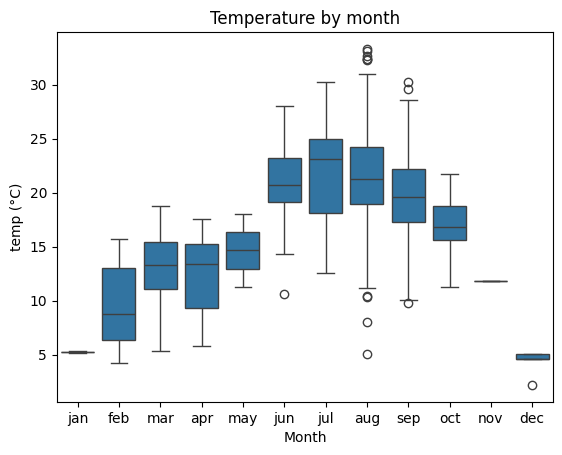

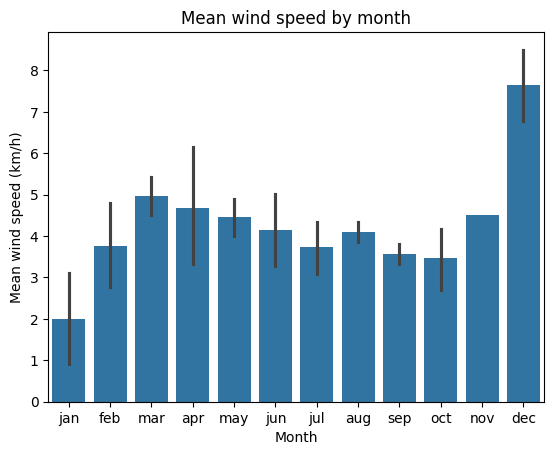

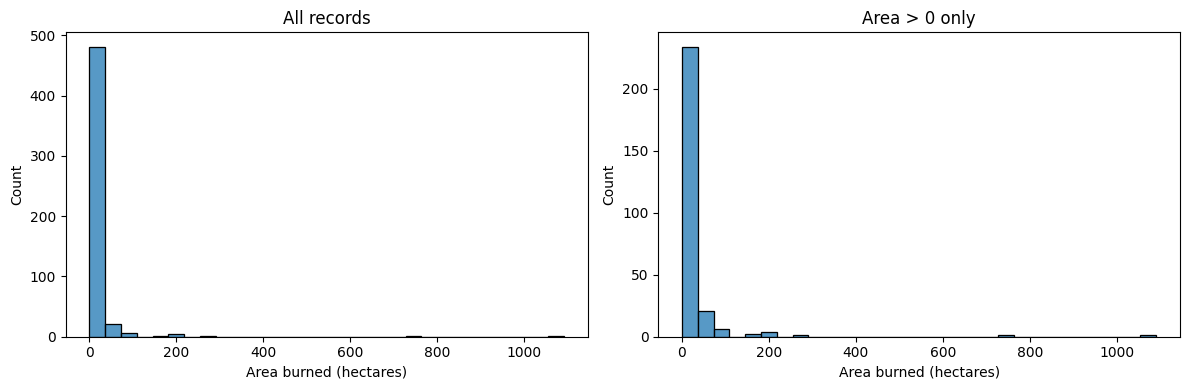

In [56]:
# 1

df = pd.read_csv(path)
df.head()

month_order = ["jan", "feb", "mar", "apr", "may", "jun",
               "jul", "aug", "sep", "oct", "nov", "dec"]

plt.figure()
sns.boxplot(data=df, x="month", y="temp", order=month_order)
plt.xlabel("Month")
plt.ylabel("temp (°C)")
plt.title("Temperature by month")
plt.show()


# 2

plt.figure()
sns.barplot(data=df, x="month", y="wind", order=month_order)
plt.xlabel("Month")
plt.ylabel("Mean wind speed (km/h)")
plt.title("Mean wind speed by month")
plt.show()


# 3

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# All records
sns.histplot(data=df, x="area", bins=30, ax=axes[0])
axes[0].set_title("All records")
axes[0].set_xlabel("Area burned (hectares)")

# Only fires that actually burned something
mask = df["area"] > 0          # True where area is above zero
burned = df[mask]              # keep only those rows
sns.histplot(data=burned, x="area", bins=30, ax=axes[1])
axes[1].set_title("Area > 0 only")
axes[1].set_xlabel("Area burned (hectares)")

plt.tight_layout()
plt.show()

# The second one, with zeros removed. In the first plot, roughly half the records have area 0, -
# - so one enormous bar at zero dominates the chart and squashes everything else into a barely visible sliver.
# Once you filter the zeros out, you can see how the non-zero fires are distributed: most are small, -
# - with a long tail of a few very large ones.

You’re right, and my earlier answer overstated it. The only visible change is that the first bar drops from about 480 to about 235, because the zero-area rows are gone. The shape is the same: one tall bar on the left and almost nothing visible elsewhere.

The cause is the skew. A few huge fires (up to about 1000 ha) stretch the x-axis, so almost all fires land in the very first bin, whether or not you remove the zeros.

## Exercise 4: Clustering the penguin data, at length

Exercise 2 clustered the penguins once, on the two bill measurements, and read the result off a
crosstab. This is the long version of the same question, on a different pair of measurements —
bill length against flipper length, beak against wing — and it asks the question Exercise 2 skipped:
how many clusters should there have been?

Nothing here needs a new dataset. The fetch cell from Exercise 2 already put `penguins_path` in
scope; if you are running this notebook from the top, reuse it.

**ℹ️ Where the tools come from**

Everything here comes from this subchapter: the elbow method, `silhouette_score`, `KMeans`, `.inertia_`,
`.fit`, `.predict` and `.labels_`. The figures in Q4 and Q5 follow the pattern of the k-means plots in this subchapter, with one `plt.scatter` call per species.

**Q1) Clean the data. Drop every row with a missing value in one of the four measurements** (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`).

Call the result `penguin_df` and print its shape. Two birds have no measurements at all; `sex` is missing for a few more, and those rows stay.

In [74]:
penguins = pd.read_csv(penguins_path)

measurements = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
penguin_df = penguins.dropna(subset=measurements)

print(penguin_df.shape)

(342, 8)


**Q2) Create an input array `X` from the `bill_length_mm` and `flipper_length_mm` columns.**

Its shape should be `(342, 2)`. Two columns, because the whole exercise is about being able to see
the answer on a flat plot.

In [75]:
X = penguin_df[["bill_length_mm", "flipper_length_mm"]].to_numpy()

# .to_numpy() turns the selection into a plain array of numbers, which is the format KMeans expects as input.

**Q3) Train k-means over a range of k, and choose k twice — once by the elbow method and once
by silhouette analysis.**

For k from 1 to 9, fit `KMeans` and record `.inertia_`, the sum of squared distances from each point
to its assigned centre. Plot inertia against k.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.8-target-penguin-elbow.png" alt="Inertia falling steeply from k equals 1 to 2 and then flattening, forming an elbow" width="450">

<em>The elbow. Inertia always falls as k rises — with one cluster per point it reaches zero — so the
number you want is not the minimum but the bend, past which each extra cluster buys much less.</em>


Then, for k from 2 to 9, fit again and record `silhouette_score(X, labels)`. Plot that against k
too. Unlike inertia, the silhouette score has a genuine maximum.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.8-target-penguin-silhouette.png" alt="Silhouette score peaking sharply at k equals 2 and declining unevenly afterwards" width="450">

<em>The silhouette score, which peaks rather than flattens.</em>


In a comment, say which k each method points at, and whether they agree.

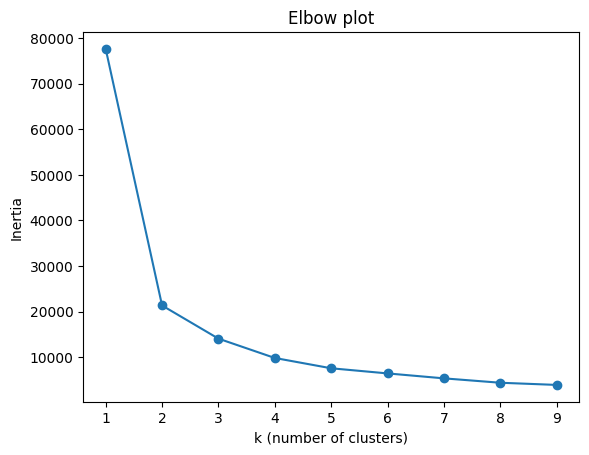

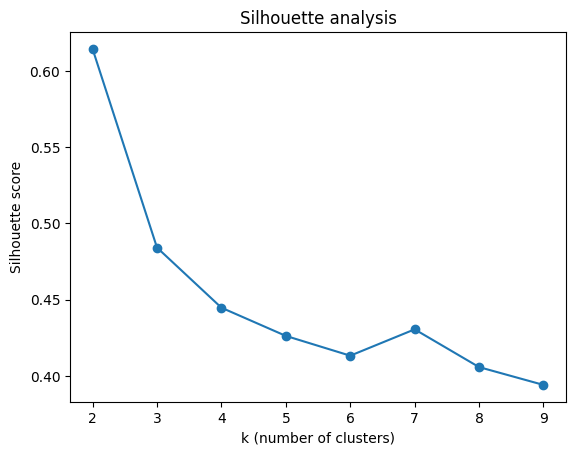

Best k by silhouette: 2


In [78]:
# 1

ks = range(1, 10)
inertias = []

for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=0)
    model.fit(X)
    inertias.append(model.inertia_)

# The for loop repeats the same steps for each k: build a KMeans model with that many clusters,
# .fit(X) to find the cluster centres, then store .inertia_ in the list inertias.
# .inertia_ is a number that the model stores after you call .fit(X).
# It measures how tight the clusters are: for every penguin, -
# - take the distance to the centre of its assigned cluster, square it, and add all of those up.
# - Small inertia means the points sit close to their centres (compact clusters). Large inertia means they are spread out.
# model.inertia_ doesn’t do anything. It is not a function that runs a calculation, it is just a stored result you read,
# The trailing underscore is scikit-learn’s convention for “this value was computed during .fit”

plt.plot(ks, inertias, marker="o")
plt.xlabel("k (number of clusters)")
plt.ylabel("Inertia")
plt.title("Elbow plot")
plt.show()


# 2

from sklearn.metrics import silhouette_score

sil_ks = range(2, 10)
sil_scores = []

for k in sil_ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=0)
    labels = model.fit_predict(X)
# Those two lines take the fitted clusters for one value of k and turn them into a single quality score.
# fit finds the cluster centres from your data X.
# predict then assigns each penguin to its nearest centre and tells you which cluster that is.
# The result, labels, is an array with one number per penguin (342 numbers).
# If k = 3, every value is 0, 1 or 2. For example, [0, 2, 1, 1, 0, ...] means the first penguin is in cluster 0,
# the second in cluster 2, the third and fourth in cluster 1, and so on.
#The numbers are just names for the clusters, with no meaning in their order.
    sil_scores.append(silhouette_score(X, labels))
# silhouette_score(X, labels) takes the measurements (X) and the cluster each penguin was given (labels), -
# - and returns one number between -1 and 1 saying how well separated the clusters are.
# It needs both because it has to know where each penguin is and which group it belongs to, -
# - in order to compare “how close am I to my own group” against “how close am I to the nearest other group”.
# sil_scores.append(...) adds that number to the end of the list sil_scores, which started out empty before the loop.

plt.plot(sil_ks, sil_scores, marker="o")
plt.xlabel("k (number of clusters)")
plt.ylabel("Silhouette score")
plt.title("Silhouette analysis")
plt.show()

best_k = sil_ks[sil_scores.index(max(sil_scores))]
print("Best k by silhouette:", best_k)
# max(sil_scores)
# sil_scores is the list of eight scores, one per k from 2 to 9.
# From your plot it looks roughly like [0.61, 0.48, 0.44, 0.43, 0.41, 0.43, 0.41, 0.39].
# max(...) returns the biggest value in that list, here about 0.61.

# sil_scores.index(...)
# .index(value) tells you the position of that value in the list, counting from 0.
# The biggest score is the first item, so this returns 0.

# sil_ks[...]
# sil_ks is range(2, 10), so its items are 2, 3, 4, ... 9. Position 0 holds the value 2, so sil_ks[0] gives 2.


# 3

# Elbow method points at k = 2   (inertia drops steeply from k = 1 to 2, then flattens)
# Silhouette analysis points at k = 2   (highest score, about 0.61)
# They agree.
# The elbow was read by eye and could have been argued as 2 or 3, but the silhouette
# score has a clear maximum at k = 2, which confirms the choice.

**Q4) Cluster with k = 3 and compare the result against the true species.**

Fit `KMeans(n_clusters=3)`, predict the labels, and store them in `penguin_df` as a `cluster`
column. Then draw one scatter of bill length against flipper length in which the *marker shape*
carries the true species and the *colour* carries the predicted cluster — three
`plt.scatter` calls, one per species, each coloured by `c=subset["cluster"]`.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.8-target-penguin-kmeans-3.png" alt="Bill length against flipper length, markers by species and colours by predicted cluster, with Gentoo cleanly separated and Adelie and Chinstrap partly mixed" width="500">

<em>The figure to replicate. Where a marker shape and its colour agree everywhere, k-means found that
species; where one shape carries two colours, it did not.</em>


Hints: pass `cmap="cividis"` and fix the colour range with `vmin=0, vmax=2` on all three calls, or
the three subsets will each be scaled separately and the colours will not mean the same thing.
Use `s=` to vary the marker size and `label=` for the legend.

In a comment: which species does k-means recover, and which two does it confuse?

In [60]:
# Q4: k = 3, then the scatter coloured by cluster and shaped by species

**Q5) Now cluster with k = 2 and draw the same figure.**

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.8-target-penguin-kmeans-2.png" alt="The same scatter with only two cluster colours, one of them spanning two species" width="500">

<em>The same plot with k = 2, the value the silhouette score preferred.</em>


The silhouette score preferred k = 2; the data has three species. In a comment, say what that
disagreement means. It is not a bug in either method.

In [61]:
# Q5: k = 2, same figure

**ℹ️ What you just did**

You chose the number of clusters twice, by two criteria that agreed with each other, and then checked both
against a ground truth that clustering never saw.

The disagreement is the lesson: both criteria pick k = 2, and the data has three species. The silhouette score measures how well separated the clusters are,
not how many kinds of thing are in the data, and on these two measurements Gentoo sits far enough
from the other two that a clean two-way split scores better than a correct three-way one. k-means
answered the question it was asked. It is worth knowing that the question is not always the one you
meant.

## Exercise 5: Marathon data analysis

The last exercise of Part I is the one dataset in the book that is not environmental, and the only
one where every row is a person. It is here because it exercises the half of seaborn that a
scatter plot and a box plot do not reach: joint distributions, a grid of pairwise relationships,
overlaid densities, and a violin plot split by a second variable.

The data is the finishing record of a marathon — roughly 37 000 runners, each with an age, a
gender, a half-way *split* time and a *final* time. The question it answers is one you can check
against your own intuition, which is what makes it a good last exercise: do people run the second
half of a marathon faster or slower than the first?

Adapted from Jake VanderPlas,
[Python Data Science Handbook](https://github.com/jakevdp/PythonDataScienceHandbook), whose
[marathon-data](https://github.com/jakevdp/marathon-data) repository is the source of the file.

**ℹ️ Beyond this subchapter**

Two of the seaborn functions below are not demonstrated in 1.8, and are linked where
they are needed:

- [`sns.PairGrid`](https://seaborn.pydata.org/generated/seaborn.PairGrid.html) — Q5, a grid of every
  pairwise combination of a set of columns
- [`sns.violinplot`](https://seaborn.pydata.org/generated/seaborn.violinplot.html) — Q7, a box plot
  whose width shows the distribution

`sns.jointplot` (including `kind="hex"`) and `sns.kdeplot` are from this subchapter, and a `PairGrid`
is used the way the `FacetGrid` of this subchapter is, by mapping a plotting function over it with `.map`.
`pd.read_csv` is from 1.5. The `datetime` module and `read_csv`'s `converters=` argument are used
only in the pre-supplied cell.

In [62]:
# Pre-supplied: download the data file and cache it locally, and parse the two time
# columns into timedeltas on the way in.
import datetime

In [63]:
import pandas as pd
import pooch

In [64]:
path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/marathon-data.csv",
    known_hash="sha256:0fff8a2bdf0cfb8887080c8132fed59399531fb836815c1935cc70823b940a85",
    fname="marathon-data.csv",
    path=pooch.os_cache("mlees"),
)

In [65]:
def convert_time(s):
    """Turn an 'hh:mm:ss' string into a timedelta."""
    hours, minutes, seconds = map(int, s.split(":"))
    return datetime.timedelta(hours=hours, minutes=minutes, seconds=seconds)

In [66]:
data = pd.read_csv(path, converters={"split": convert_time, "final": convert_time})
data.head()

,age,gender,split,final
0,33,M,0 days 01:05:38,0 days 02:08:51
1,32,M,0 days 01:06:26,0 days 02:09:28
2,31,M,0 days 01:06:49,0 days 02:10:42
3,38,M,0 days 01:06:16,0 days 02:13:45
4,31,M,0 days 01:06:32,0 days 02:13:59


**Q1) Add two columns, `split_sec` and `final_sec`, holding the same two times in seconds.**

A `timedelta` column is awkward to plot and awkward to divide. Convert both with
`.dt.total_seconds()`, then print the first few rows to check.

**⚠️ Why not `.astype(int) / 1e9`?**

Earlier versions of this exercise converted with `data["split"].astype(int) / 1e9`, which reads the
integer underneath the timedelta and divides by a billion — correct only while pandas stored
timedeltas in nanoseconds. Current pandas stores them in microseconds, so that expression now
returns a number a thousand times too small, silently and without an error.

`.dt.total_seconds()` asks for the quantity you want rather than for the bytes that happen to
represent it, and keeps working when the representation changes. The split *fraction* in Q3 is a
ratio, so it survives either way — which is exactly what would have let the bug through.

In [67]:
# Q1: add split_sec and final_sec, then check the first rows

**Q2) Use `sns.jointplot` to plot `final_sec` against `split_sec`.**

Use `kind="hex"` for the two-dimensional histogram, and add the line a runner of perfectly even
pace would lie on:

```python
g.ax_joint.plot(np.linspace(4000, 16000), np.linspace(8000, 32000), ":k")
```

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.8-target-marathon-jointplot.png" alt="A hexagonal-bin joint distribution of final time against split time, the dense band lying above a dotted line of even pace" width="450">

<em>The figure to replicate. The dotted line is where a runner whose second half took exactly as long
as the first would fall.</em>


The distribution lies almost entirely *above* the line: most people slow down over the course of
the race. Runners who do the opposite are said to have *negative-split* the race.

In [68]:
# Q2: the joint distribution, with the even-pace line

**Q3) Add a `split_frac` column measuring how much each runner sped up or slowed down.**

$$\text{split\_frac} = 1 - 2 \times \frac{\text{split\_sec}}{\text{final\_sec}}$$

It is zero for an exactly even race, negative for a negative split, and positive for slowing down.

In [69]:
# Q3: add split_frac

**Q4) Print how many runners had a `split_frac` below zero.**

You should get 251 — out of nearly 37 000.

In [70]:
# Q4: count the negative splits

**Q5) Use `sns.PairGrid` to look for what `split_frac` correlates with.**

Build the grid over `age`, `split_sec`, `final_sec` and `split_frac`, with `hue="gender"` so men and
women are drawn separately, and `palette="RdBu_r"`. Map `plt.scatter` over it and add a legend.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.8-target-marathon-pairgrid.png" alt="A four-by-four grid of pairwise scatter plots of age, split time, final time and split fraction, coloured by gender" width="100%">

<em>The figure to replicate.</em>


In a comment, name the one pair in the grid that is a near-perfect straight line, and say why that
particular relationship is not a finding about runners.

In [71]:
# Q5: the PairGrid

**Q6) Compare the split-fraction distributions of men and women with `sns.kdeplot`.**

One filled density per gender on the same axes, labelled, with a legend.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.8-target-marathon-kde.png" alt="Two overlaid density curves of split fraction, one per gender, both centred above zero" width="450">

<em>The figure to replicate.</em>


Hint: seaborn renamed this argument — it is `fill=True` now, not `shade=True`.

In [72]:
# Q6: one filled density per gender

**Q7) Split the comparison by age as well, with `sns.violinplot`.**

Add an `age_decade` column with `10 * (data["age"] // 10)`, then draw `split_frac` against
`age_decade` with `hue="gender"`. `split=True` puts the two genders on either side of the same
violin, which is what makes them comparable decade by decade.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.8-target-marathon-violin.png" alt="Split violins of split fraction by age decade, each violin divided between the two genders" width="500">

<em>The figure to replicate.</em>


In a comment: the violins for the oldest decades are much narrower than the rest. Before reading
that as "older runners pace more consistently", check how many runners are in those decades.

In [73]:
# Q7: add age_decade, then the split violins

**ℹ️ What you just did**

You derived a quantity that was not in the file — the split fraction — from two that were, then
looked at it four ways: against its own inputs, against every other column at once, split by one
categorical variable, then by two.

The Q7 warning is the one to carry forward. A violin plot shows you the shape of a distribution
and tells you nothing about how many points went into it, so a narrow violin over the fifteen runners in
their eighties looks much like a confident result over the twelve thousand in their forties. Counting the rows behind a group is not an
extra check to run when something looks surprising; it is part of reading the plot.

That closes Part I. Everything after this is machine learning proper — but it is built on exactly
what you have been doing here: get the data, check what is actually in it, derive what you need,
and plot it before you believe it.